In [ ]:

print("Welcome to House Price Prediction Project!")
print("Project: Data Science using Python")
print("Step 1: Python environment is ready!")

Welcome to House Price Prediction Project!
Project: Data Science using Python
Step 1: Python environment is ready!


In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

# Load the housing dataset
housing = fetch_california_housing(as_frame=True)

df = housing.frame

# Display first 5 rows
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!
Dataset shape: (20640, 9)

First 5 rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [ ]:


# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

# Dataset information
print("\nDataset information:")
df.info()

# Statistical summary
print("\nStatistical summary:")
display(df.describe())

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Dataset columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


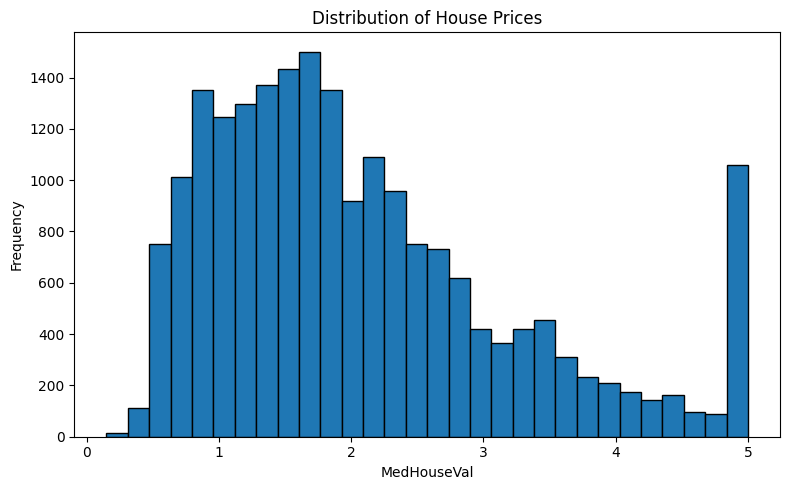

House price graph created successfully!


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check dataset columns
print("Dataset columns:")
print(df.columns.tolist())

# Plot using the correct column names
if "median_house_value" in df.columns:
    target = "median_house_value"
elif "MedHouseVal" in df.columns:
    target = "MedHouseVal"
else:
    target = None

if target is not None:
    plt.figure(figsize=(8, 5))
    plt.hist(df[target].dropna(), bins=30, edgecolor="black")
    plt.title("Distribution of House Prices")
    plt.xlabel(target)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
    print("House price graph created successfully!")
else:
    print("House price column nahi mila. Upar diye column names check karo.")

In [ ]:


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Identify target column
if "median_house_value" in df.columns:
    target = "median_house_value"
elif "MedHouseVal" in df.columns:
    target = "MedHouseVal"
else:
    raise ValueError("House price target column nahi mila!")

# Prepare features and target
X = df.drop(columns=[target])
y = df[target]

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True)

# Fill missing values
X = X.fillna(X.median())

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model training completed successfully!")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Model training completed successfully!
MAE: 0.53
RMSE: 0.75
R2 Score: 0.5758


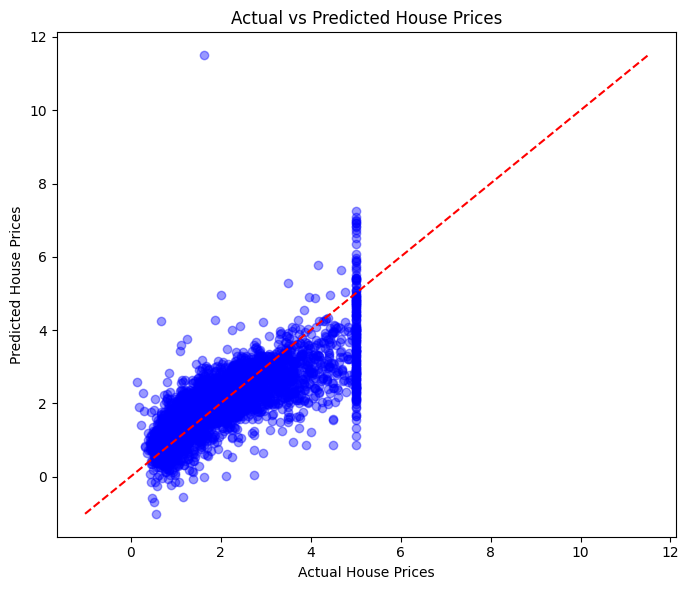

Actual vs Predicted graph created!


In [ ]:


import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.4, color="blue")

# Perfect prediction reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

print("Actual vs Predicted graph created!")

In [ ]:


results = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": y_pred[:10]
})

results["Predicted Price"] = results["Predicted Price"].round(2)
display(results)

,Actual Price,Predicted Price
0,0.47700,0.72
1,0.45800,1.76
2,5.00001,2.71
3,2.18600,2.84
4,2.78000,2.60
5,1.58700,2.01
6,1.98200,2.65
7,1.57500,2.17
8,3.40000,2.74
9,4.46600,3.92
